<a href="https://colab.research.google.com/github/evallejog/DATA-ANAYTICS-ML-CHALLENGE-C3/blob/main/S12_ML_Challenge_Semana14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio Olist: modelos supervisados y optimización (Semanas 12 y 14)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir una línea base para anticipar entregas tardías y evaluar, con una comparación controlada, si PCA y distintos niveles de regularización mejoran la predicción.

Este notebook conserva la preparación de datos, muestra individual y actividades de la semana 12. Al final incorpora íntegramente el experimento de la semana 14: PCA con 90 % de varianza, cuatro configuraciones de regresión logística, métricas, costo didáctico y prueba Kolmogorov-Smirnov. Ejecute desde el inicio; la prueba final permanece reservada y no participa en la selección de modelos.


## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 27
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 27 | Semilla: 1027
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: cbcbd93352d9


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [8]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [9]:
# TODO 1. Entrene el modelo y genere predicciones.
from sklearn.base import clone

# Comparación de las dos opciones de class_weight en VALIDACIÓN (la prueba no se toca).
# Cada candidato recibe una copia independiente del preprocesamiento.
comparacion = []
for opcion in [None, 'balanced']:
    candidato = make_pipeline(clone(preprocesamiento),
                              LogisticRegression(class_weight=opcion, max_iter=1000))
    candidato.fit(X_train, y_train)
    p = candidato.predict(X_valid)
    pr_ = candidato.predict_proba(X_valid)[:, 1]
    tn_, fp_, fn_, tp_ = confusion_matrix(y_valid, p).ravel()
    comparacion.append({
        'class_weight': str(opcion),
        'accuracy': accuracy_score(y_valid, p),
        'precision': precision_score(y_valid, p, zero_division=0),
        'recall': recall_score(y_valid, p),
        'f1': f1_score(y_valid, p, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, pr_),
        'ap': average_precision_score(y_valid, pr_),
        'tardios_detectados': int(tp_),
        'tardios_perdidos': int(fn_),
        'costo_brl': 8 * fp_ + 35 * fn_,
    })
print(pd.DataFrame(comparacion).round(3).to_string(index=False))

# Decisión: 'balanced' (justificación en la sección 6, pregunta 1).
peso_clases = 'balanced'  # Opción: None

modelo = make_pipeline(preprocesamiento,
                       LogisticRegression(class_weight=peso_clases, max_iter=1000))
modelo.fit(X_train, y_train)
pred = modelo.predict(X_valid)
print('\nModelo final entrenado con class_weight =', peso_clases)


class_weight  accuracy  precision  recall    f1  roc_auc    ap  tardios_detectados  tardios_perdidos  costo_brl
        None     0.932      0.333   0.003 0.006    0.691 0.162                   1               355      12441
    balanced     0.652      0.113   0.601 0.190    0.693 0.157                 214               142      18442

Modelo final entrenado con class_weight = balanced


## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [10]:
# TODO 2. Calcule las métricas y muestre la matriz de confusión.
proba = modelo.predict_proba(X_valid)[:, 1]   # probabilidad de la clase 1 (tardío)
medidas = {
    'accuracy': accuracy_score(y_valid, pred),
    'precision': precision_score(y_valid, pred, zero_division=0),
    'recall': recall_score(y_valid, pred),
    'f1': f1_score(y_valid, pred, zero_division=0),
    'roc_auc': roc_auc_score(y_valid, proba),   # AUC con probabilidades, no con clases
    'ap': average_precision_score(y_valid, proba),
}

for nombre, valor in medidas.items():
    print(f'{nombre:10s}: {valor:.3f}')
print(f"\nPrevalencia de tardíos en validación (AP de un modelo al azar): {y_valid.mean():.3f}")

cm = confusion_matrix(y_valid, pred)
print('\nMatriz de confusión (filas = real, columnas = predicho):')
print(pd.DataFrame(cm,
                   index=['real: a tiempo (0)', 'real: tardío (1)'],
                   columns=['pred: a tiempo (0)', 'pred: tardío (1)']))


accuracy  : 0.652
precision : 0.113
recall    : 0.601
f1        : 0.190
roc_auc   : 0.693
ap        : 0.157

Prevalencia de tardíos en validación (AP de un modelo al azar): 0.068

Matriz de confusión (filas = real, columnas = predicho):
                    pred: a tiempo (0)  pred: tardío (1)
real: a tiempo (0)                3210              1684
real: tardío (1)                   142               214


### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [11]:
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'
analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)
analisis['fp'] = ((analisis['pred'] == 1) & (analisis['is_late'] == 0)).astype(int)
analisis['fn'] = ((analisis['pred'] == 0) & (analisis['is_late'] == 1)).astype(int)

# TODO 3. Agrupe por mes_compra y customer_state.
def errores_por(columna):
    tabla = (analisis.groupby(columna)
             .agg(pedidos=('error', 'size'),
                  errores=('error', 'sum'),
                  falsos_pos=('fp', 'sum'),
                  falsos_neg=('fn', 'sum'),
                  tasa_error_pct=('error', lambda s: 100 * s.mean()),
                  tardios_reales_pct=('is_late', lambda s: 100 * s.mean()))
             .round(1))
    return tabla

por_mes = errores_por('mes_compra').sort_index()
por_estado = errores_por('customer_state').sort_values('tasa_error_pct', ascending=False)

print('Error global en validación:', round(100 * analisis['error'].mean(), 1), '%\n')
print('--- Error por mes de compra ---')
print(por_mes.to_string())
print('\n--- Error por estado del cliente (ordenado por % de error) ---')
print(por_estado.to_string())

# Los estados con pocos pedidos producen porcentajes inestables; se resaltan los de n >= 100.
print('\n--- Estados con al menos 100 pedidos en validación ---')
print(por_estado[por_estado['pedidos'] >= 100].to_string())


Error global en validación: 34.8 %

--- Error por mes de compra ---
            pedidos  errores  falsos_pos  falsos_neg  tasa_error_pct  tardios_reales_pct
mes_compra                                                                              
1               447      149         142           7            33.3                 5.1
2               438      151         133          18            34.5                11.6
3               512      221         196          25            43.2                16.0
4               464      152         141          11            32.8                 4.7
5               542      216         210           6            39.9                 4.6
6               498      119         116           3            23.9                 1.8
7               550      229         222           7            41.6                 2.7
8               607      276         269           7            45.5                 4.4
9               240       90          86  

### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [12]:
# TODO 4. Calcule el costo total con la matriz de confusión.
tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
costo_fp_fn = 8 * fp + 35 * fn

print(f'Falsos positivos (FP): {fp}  ->  R$ {8 * fp:,.0f}')
print(f'Falsos negativos (FN): {fn}  ->  R$ {35 * fn:,.0f}')
print(f'Costo total de errores: R$ {costo_fp_fn:,.0f}')

# Referencia: costo de no intervenir nunca (todos los tardíos se pierden).
costo_no_hacer_nada = 35 * int(y_valid.sum())
print(f'\nCosto de predecir siempre "a tiempo": R$ {costo_no_hacer_nada:,.0f}')


Falsos positivos (FP): 1684  ->  R$ 13,472
Falsos negativos (FN): 142  ->  R$ 4,970
Costo total de errores: R$ 18,442

Costo de predecir siempre "a tiempo": R$ 12,460


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [13]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [14]:
from sklearn.base import clone

# Cada modelo recibe una copia independiente del preprocesamiento.
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])
pred_dias = modelo_reg.predict(X_valid)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)
print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.14 días


## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

Respuesta:

**Comparación en validación (5.250 pedidos, 356 tardíos = 6,8 %):**

| Modelo | Accuracy | Recall | F1 |
|---|---|---|---|
| Referencia (`DummyClassifier`, siempre "a tiempo") | 0,932 | 0,000 | 0,000 |
| Regresión logística, `class_weight=None` | 0,932 | 0,003 | 0,006 |
| Regresión logística, `class_weight='balanced'` (elegido) | 0,654 | 0,604 | 0,191 |

La Accuracy engaña: la referencia saca 0,932 sin detectar ni un solo pedido tardío, porque el 93,2 % de los pedidos llega a tiempo. Con `class_weight=None` la regresión logística se comporta casi igual que la referencia: mantiene una Accuracy de 0,932, pero solo detecta 1 de los 356 pedidos tardíos (Recall 0,003, F1 0,006). Su Precision de 0,333 se calcula sobre apenas 3 pedidos marcados como tardíos, por lo que no es una señal fiable. Con el umbral por defecto de 0,5 el modelo casi nunca se atreve a decir "tardío", porque la clase minoritaria pesa muy poco en el entrenamiento.

Elegí `class_weight='balanced'` porque es el único que produce un modelo útil para el objetivo del caso (anticipar retrasos): detecta 215 de 356 pedidos tardíos (Recall 0,604) y el F1 sube de 0,006 a 0,191. El precio es una caída de la Accuracy a 0,654 y una Precision de solo 0,114 (de cada 100 pedidos marcados como riesgosos, unos 11 realmente se retrasan), con 1.677 falsos positivos. Además, el ROC-AUC (0,693 con `balanced` frente a 0,691 con `None`) y el AP (0,157 frente a 0,162) son prácticamente iguales: `class_weight` no mejora la capacidad de ordenar pedidos por riesgo, solo mueve el punto de corte efectivo.

**Limitación importante:** con los costos supuestos (R$ 8 por FP y R$ 35 por FN) el modelo `balanced` cuesta R$ 18.351 en validación, más que el modelo `None` (R$ 12.441) y que no hacer nada (R$ 12.460, que equivale a perder los 356 tardíos a R$ 35). Es decir, elegí `balanced` por Recall y F1, pero con el umbral 0,5 no se justifica económicamente. Eso indica que el problema no se resuelve solo con `class_weight`, sino con la elección del umbral y con mejores variables (ver pregunta 3). El AP de 0,157 es 2,3 veces la prevalencia (0,068): hay señal, pero modesta.


2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

Respuesta:

**Por mes de compra.** El error global es 34,6 % (1.818 errores sobre 5.250 pedidos). Los meses con más error son agosto (45,3 %, 275 errores de 607 pedidos) y marzo (43,2 %, 221 de 512), seguidos por julio (41,6 %) y mayo (39,5 %). Los de menor error son diciembre (13,6 %) y junio (23,9 %). Casi todo el error es de falsos positivos: en agosto 268 de los 275 errores son FP, y en julio 222 de 229. Son meses con pocos retrasos reales (4,4 % en agosto y 2,7 % en julio) en los que el modelo igualmente marca muchos pedidos como riesgosos. Los falsos negativos se concentran en los meses con más retrasos reales: noviembre (15,5 % de tardíos, 33 FN), marzo (16,0 %, 25 FN) y febrero (11,6 %, 17 FN). Esos picos de retraso parecen un efecto de calendario que el modelo no captura bien con las variables disponibles.

**Por estado del cliente.** Entre los estados con al menos 100 pedidos, el error es mayor en Bahía (63,0 %), Río de Janeiro (59,5 %, 405 errores de 681 pedidos), Santa Catarina (58,3 %) y Espírito Santo (54,8 %), y menor en Paraná (14,3 %), São Paulo (21,4 %, con 2.154 pedidos) y Minas Gerais (22,0 %). En Río de Janeiro, 391 de los 405 errores son falsos positivos, y es un estado con retrasos reales más altos (12,6 %) que São Paulo (4,3 %), por lo que el modelo lo trata como "zona riesgosa" y marca muchos pedidos que sí llegan a tiempo. Los estados con pocos pedidos (por ejemplo RR con 1, SE con 18) tienen porcentajes de error inestables y no deben interpretarse por sí solos.

**Relación con el costo.** Con `balanced` el error es sobre todo de tipo FP: 1.677 FP frente a 141 FN. Aunque un FN cuesta R$ 35 (4,4 veces un FP de R$ 8), los FP suman R$ 13.416 (73 % del costo) y los FN R$ 4.935 (27 %). Los segmentos con más error (agosto, marzo, Río de Janeiro, Bahía) son por tanto los que más costo generan por falsas alarmas. El modelo gana Recall a costa de revisar o intervenir muchos pedidos que no lo necesitaban. Para que marcar un pedido compense con estos costos, la probabilidad de retraso debería superar 8/(8+35) = 18,6 %, y la Precision actual es 11,4 %.


3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

Respuesta:

**Mejora propuesta: variable de ruta y umbral por costo.**

1. *Información del vendedor y cliente (ruta).* Crear la variable categórica `ruta = estado_vendedor + '_' + customer_state` (por ejemplo `SP_RJ`), porque el retraso depende del trayecto concreto y no de cada estado por separado. Ahora el modelo solo ve `customer_state` y `estado_vendedor` por separado, que en una regresión lineal con One-Hot se suman sin capturar su interacción. Las rutas con pocos pedidos se agruparán en una categoría "otras", y esa agrupación se decidirá solo con los datos de entrenamiento, dentro del `Pipeline`.
2. *Tratamiento de categóricas y modelo.* Probar también un `HistGradientBoostingClassifier` con la variable de ruta y `categoria_principal` como categóricas nativas, que capta relaciones no lineales entre `dias_prometidos`, el flete, el peso y la ruta.
3. *Umbral por costo.* En lugar de usar 0,5, elegir el umbral con validación cruzada dentro de entrenamiento minimizando 8·FP + 35·FN, porque los resultados de esta semana muestran que el punto de corte pesa más que `class_weight`.

**Cómo lo verificaré con la misma partición:** misma muestra (ID 27, semilla 1027), mismas particiones y mismo `X_valid`, comparando contra esta línea base: ROC-AUC 0,693, AP 0,157, F1 0,191, Recall 0,604 y costo R$ 18.351 (R$ 12.460 si no se hace nada). Consideraré que hay mejora si sube el AP y el ROC-AUC (métricas que no dependen del umbral) y si el costo en validación queda por debajo de R$ 12.460, que es lo mínimo para que el modelo supere a no intervenir. La prueba final no se toca hasta la semana 16.


## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [15]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports/S12_resultados_ID_27.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# 8. Semana 14 — PCA y evaluación de mejoras al modelo

En esta sección se trabaja con **la misma muestra individual y las mismas particiones** definidas anteriormente: 24.500 pedidos de entrenamiento, 5.250 de validación y 5.250 de prueba final. La selección de modelos se realiza exclusivamente con validación. La prueba final no se consulta.

La comparación controlada utiliza `class_weight='balanced'` y umbral de clasificación `0.50` en los cuatro experimentos. Solo cambian PCA y el parámetro `C` de la regresión logística.

| Experimento | Variables numéricas | C | Interpretación |
|---|---|---:|---|
| A | Sin PCA | 1.0 | Referencia S14 |
| B | PCA, 90 % de varianza | 1.0 | Efecto de PCA frente a A |
| C | PCA, 90 % de varianza | 0.1 | Regularización más fuerte frente a B |
| D | PCA, 90 % de varianza | 10.0 | Regularización más débil frente a B |

`C` controla inversamente la intensidad de regularización: un valor pequeño penaliza más los coeficientes. PCA resume la variabilidad de las variables numéricas, pero conservar el 90 % de la varianza **no significa** obtener 90 % de exactitud ni garantiza mejores predicciones.


## 8.1. Preparación y control de las particiones

Las transformaciones se ajustan dentro de `Pipeline` y `ColumnTransformer`, únicamente con `X_train`. La ruta numérica imputa la mediana y estandariza; para B, C y D se agrega PCA. La ruta categórica imputa la categoría más frecuente y aplica One-Hot Encoding.

Así se evita que la mediana, la escala, las categorías o las componentes principales aprendan información de validación. Las cuatro variables categóricas se mantienen separadas y no pasan por PCA.


In [16]:
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, roc_auc_score,
                             confusion_matrix)
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt

# Comprobaciones: se usan las particiones individuales de la semana 12.
assert len(train) == 24500 and len(valid) == 5250 and len(test) == 5250
assert set(train['order_id']).isdisjoint(valid['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(valid['order_id']).isdisjoint(test['order_id'])
assert len(columnas_numericas) > 0 and len(columnas_categoricas) > 0

print(f'ID estudiante: {identificador} | Semilla: {semilla}')
print(f'Train: {len(X_train):,} | Validación: {len(X_valid):,} | Prueba reservada: {len(test):,}')
print(f'Variables numéricas originales: {len(columnas_numericas)}')
print(f'Variables categóricas: {len(columnas_categoricas)}')
print(f'Prevalencia de retrasos en train: {y_train.mean():.3%}')
print(f'Prevalencia de retrasos en validación: {y_valid.mean():.3%}')

ID estudiante: 27 | Semilla: 1027
Train: 24,500 | Validación: 5,250 | Prueba reservada: 5,250
Variables numéricas originales: 24
Variables categóricas: 4
Prevalencia de retrasos en train: 6.776%
Prevalencia de retrasos en validación: 6.781%


## 8.2. PCA y varianza explicada acumulada

Se ajusta una ruta numérica preliminar con imputación y estandarización sobre entrenamiento, para visualizar cuántas componentes se necesitan para alcanzar al menos 90 % de la varianza. Esta gráfica es descriptiva; el ajuste definitivo de PCA también se realizará dentro de cada pipeline del experimento para evitar fuga de información.


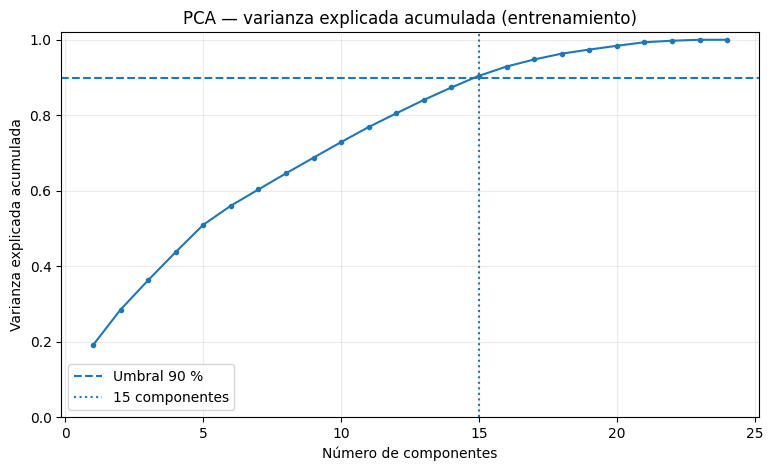

Variables numéricas iniciales: 24
Componentes necesarias para >= 90 %: 15
Varianza acumulada retenida: 90.45%
Dimensiones reducidas en: 9 columnas


In [17]:
# Ajuste descriptivo SOLO sobre entrenamiento.
preparacion_numerica_pca = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)
X_train_num_esc = preparacion_numerica_pca.fit_transform(X_train[columnas_numericas])

pca_exploratorio = PCA(svd_solver='full')
pca_exploratorio.fit(X_train_num_esc)

varianza_individual = pca_exploratorio.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_individual)
n_componentes_90 = int(np.searchsorted(varianza_acumulada, 0.90) + 1)
porcentaje_retenido = float(varianza_acumulada[n_componentes_90 - 1])

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(varianza_acumulada) + 1), varianza_acumulada,
         marker='o', markersize=3)
plt.axhline(0.90, linestyle='--', label='Umbral 90 %')
plt.axvline(n_componentes_90, linestyle=':', label=f'{n_componentes_90} componentes')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA — varianza explicada acumulada (entrenamiento)')
plt.ylim(0, 1.02)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print(f'Variables numéricas iniciales: {len(columnas_numericas)}')
print(f'Componentes necesarias para >= 90 %: {n_componentes_90}')
print(f'Varianza acumulada retenida: {porcentaje_retenido:.2%}')
print(f'Dimensiones reducidas en: {len(columnas_numericas) - n_componentes_90} columnas')

### Interpretación de PCA

Registre a partir de la salida: (1) cuántas variables numéricas había inicialmente, (2) cuántas componentes se conservaron, (3) qué proporción de dimensiones se redujo y (4) qué información podría perderse al resumir los datos. Una variable de baja varianza puede contener señal predictiva; por eso la curva de PCA no sustituye la evaluación de Recall, F1 y Average Precision.


## 8.3. Construcción de los cuatro experimentos

Cada modelo utiliza la misma muestra, partición, variables, `class_weight='balanced'`, `max_iter=2000` y umbral 0.50. La imputación, estandarización, PCA y codificación se ajustan dentro del pipeline de cada modelo.


In [18]:
def crear_preprocesamiento_s14(usar_pca):
    # La ruta numérica cambia solo por la inclusión de PCA.
    pasos_numericos = [
        ('imputacion', SimpleImputer(strategy='median')),
        ('escalado', StandardScaler())
    ]
    if usar_pca:
        pasos_numericos.append(
            ('pca', PCA(n_components=0.90, svd_solver='full'))
        )
    pipeline_numerico = make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        *([PCA(n_components=0.90, svd_solver='full')] if usar_pca else [])
    )

    pipeline_categorico = make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    )
    return ColumnTransformer(
        transformers=[
            ('numericas', pipeline_numerico, columnas_numericas),
            ('categoricas', pipeline_categorico, columnas_categoricas)
        ],
        remainder='drop'
    )

configuraciones_s14 = {
    'A': {'usar_pca': False, 'C': 1.0, 'descripcion': 'Sin PCA, C=1.0'},
    'B': {'usar_pca': True,  'C': 1.0, 'descripcion': 'PCA 90 %, C=1.0'},
    'C': {'usar_pca': True,  'C': 0.1, 'descripcion': 'PCA 90 %, C=0.1'},
    'D': {'usar_pca': True,  'C': 10.0, 'descripcion': 'PCA 90 %, C=10.0'}
}

modelos_s14 = {}
resultados_s14 = []
predicciones_s14 = {}
probabilidades_s14 = {}

for nombre, cfg in configuraciones_s14.items():
    prepro_s14 = crear_preprocesamiento_s14(cfg['usar_pca'])
    clasificador = LogisticRegression(
        C=cfg['C'],
        penalty='l2',
        solver='lbfgs',
        class_weight='balanced',
        max_iter=2000,
        random_state=semilla
    )
    pipeline = make_pipeline(prepro_s14, clasificador)
    pipeline.fit(X_train, y_train)

    # Umbral fijo 0.50 para que la comparación sea controlada.
    prob = pipeline.predict_proba(X_valid)[:, 1]
    prediccion = (prob >= 0.50).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, prediccion, labels=[0, 1]).ravel()

    fila = {
        'experimento': nombre,
        'configuracion': cfg['descripcion'],
        'C': cfg['C'],
        'accuracy': accuracy_score(y_valid, prediccion),
        'precision': precision_score(y_valid, prediccion, zero_division=0),
        'recall': recall_score(y_valid, prediccion, zero_division=0),
        'f1': f1_score(y_valid, prediccion, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, prob),
        'average_precision': average_precision_score(y_valid, prob),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'costo_brl': int(8 * fp + 35 * fn)
    }
    modelos_s14[nombre] = pipeline
    predicciones_s14[nombre] = prediccion
    probabilidades_s14[nombre] = prob
    resultados_s14.append(fila)

resultados_s14 = pd.DataFrame(resultados_s14).set_index('experimento')
print('Resultados en VALIDACIÓN (umbral = 0.50):')
display(resultados_s14.round(4))


Resultados en VALIDACIÓN (umbral = 0.50):


,configuracion,C,accuracy,precision,recall,f1,roc_auc,average_precision,TN,FP,FN,TP,costo_brl
experimento,,,,,,,,,,,,,
A,"Sin PCA, C=1.0",1.0,0.6522,0.1128,0.6011,0.1899,0.6929,0.1566,3210,1684,142,214,18442
B,"PCA 90 %, C=1.0",1.0,0.6274,0.1090,0.6264,0.1857,0.6702,0.1384,3071,1823,133,223,19239
C,"PCA 90 %, C=0.1",0.1,0.6236,0.1079,0.6264,0.1841,0.6747,0.1387,3051,1843,133,223,19399
D,"PCA 90 %, C=10.0",10.0,0.6276,0.1090,0.6264,0.1858,0.6696,0.1377,3072,1822,133,223,19231


## 8.4. Comparación visual y análisis de errores

Accuracy puede ser alta incluso cuando el modelo no detecta retrasos. Por eso se contrastan Precision, Recall, F1 y Average Precision, además de la matriz de confusión y el costo didáctico. Average Precision resume la curva Precision–Recall a distintos umbrales; no depende de fijar la decisión en 0.50.


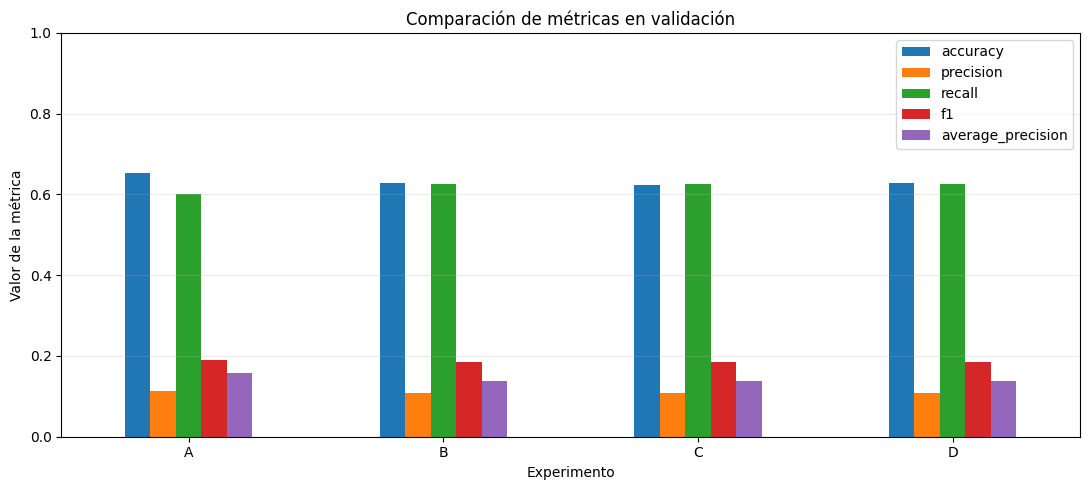

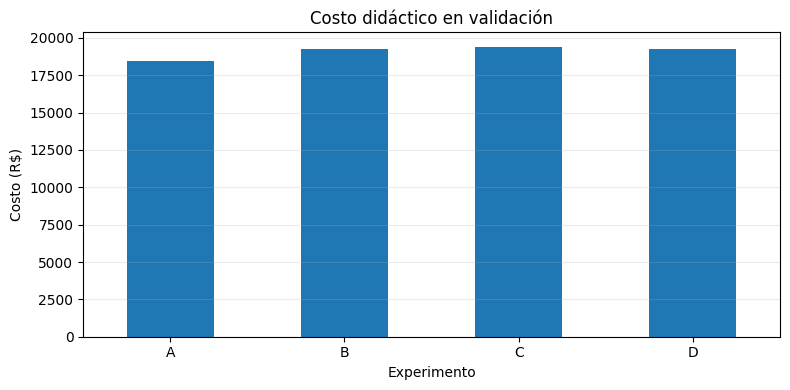


Matriz de confusión — experimento A


,Predicho a tiempo (0),Predicho tardío (1)
Real a tiempo (0),3210,1684
Real tardío (1),142,214



Matriz de confusión — experimento B


,Predicho a tiempo (0),Predicho tardío (1)
Real a tiempo (0),3071,1823
Real tardío (1),133,223



Matriz de confusión — experimento C


,Predicho a tiempo (0),Predicho tardío (1)
Real a tiempo (0),3051,1843
Real tardío (1),133,223



Matriz de confusión — experimento D


,Predicho a tiempo (0),Predicho tardío (1)
Real a tiempo (0),3072,1822
Real tardío (1),133,223


In [19]:
metricas_grafica = ['accuracy', 'precision', 'recall', 'f1', 'average_precision']
ax = resultados_s14[metricas_grafica].plot(
    kind='bar', figsize=(11, 5), ylim=(0, 1), rot=0
)
ax.set_title('Comparación de métricas en validación')
ax.set_ylabel('Valor de la métrica')
ax.set_xlabel('Experimento')
ax.grid(axis='y', alpha=0.25)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

ax = resultados_s14['costo_brl'].plot(kind='bar', figsize=(8, 4), rot=0)
ax.set_title('Costo didáctico en validación')
ax.set_ylabel('Costo (R$)')
ax.set_xlabel('Experimento')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

for nombre in configuraciones_s14:
    print(f'\nMatriz de confusión — experimento {nombre}')
    cm_s14 = confusion_matrix(y_valid, predicciones_s14[nombre], labels=[0, 1])
    display(pd.DataFrame(cm_s14,
                         index=['Real a tiempo (0)', 'Real tardío (1)'],
                         columns=['Predicho a tiempo (0)', 'Predicho tardío (1)']))

## 8.5. Costo empresarial supuesto

El costo del ejercicio es ilustrativo, no un costo contable observado de Olist:

- Falso positivo (FP): R$ 8.
- Falso negativo (FN): R$ 35.
- Costo total: `8 * FP + 35 * FN`.

Se compara también con la política de no emitir alertas (predecir siempre “a tiempo”), cuyo costo es `35 * número de tardíos reales` en validación. Un modelo con más Recall no necesariamente resulta más económico si produce demasiadas falsas alarmas.


In [20]:
costo_no_intervenir_s14 = 35 * int(np.asarray(y_valid).sum())
resumen_costos_s14 = resultados_s14[['FP', 'FN', 'costo_brl']].copy()
resumen_costos_s14['costo_FP_brl'] = 8 * resumen_costos_s14['FP']
resumen_costos_s14['costo_FN_brl'] = 35 * resumen_costos_s14['FN']

print(f'Costo de no intervenir (todos puntuales): R$ {costo_no_intervenir_s14:,.0f}')
display(resumen_costos_s14)
mejor_costo = resultados_s14['costo_brl'].idxmin()
print(f'Menor costo entre A–D: experimento {mejor_costo} '
      f'(R$ {resultados_s14.loc[mejor_costo, "costo_brl"]:,.0f})')

if resultados_s14.loc[mejor_costo, 'costo_brl'] < costo_no_intervenir_s14:
    print('Según los costos didácticos, esta configuración cuesta menos que no intervenir.')
else:
    print('Ninguna configuración A–D supera económicamente la política de no intervenir '
          'bajo los costos didácticos y el umbral 0.50.')

Costo de no intervenir (todos puntuales): R$ 12,460


,FP,FN,costo_brl,costo_FP_brl,costo_FN_brl
experimento,,,,,
A,1684,142,18442,13472,4970
B,1823,133,19239,14584,4655
C,1843,133,19399,14744,4655
D,1822,133,19231,14576,4655


Menor costo entre A–D: experimento A (R$ 18,442)
Ninguna configuración A–D supera económicamente la política de no intervenir bajo los costos didácticos y el umbral 0.50.


## 8.6. Prueba Kolmogorov-Smirnov (KS) para dos muestras

Se contrasta la distribución de `valor_flete` en entrenamiento y validación. La prueba no compara modelos ni mide su desempeño.

- **H₀:** las dos muestras proceden de la misma distribución de `valor_flete`.
- **H₁:** las distribuciones de `valor_flete` son diferentes.
- Nivel de significancia: α = 0.05.
- Estadístico D: máxima distancia absoluta entre las funciones de distribución acumulada empíricas.

Si `p < 0.05`, se rechaza H₀. Si `p >= 0.05`, no se rechaza H₀; esto no demuestra que las distribuciones sean idénticas.


Comparación: valor_flete entre entrenamiento y validación
n entrenamiento: 24,500
n validación: 5,250
Estadístico D: 0.009701
Valor p: 0.806716
Nivel de significancia: 0.05
Decisión: No rechazar H0
Interpretación: No hay evidencia suficiente para afirmar que las distribuciones de valor_flete difieren. Esto no prueba que sean idénticas.

Resumen descriptivo:


,entrenamiento,validacion
count,24500.000000,5250.000000
mean,22.873935,23.351272
std,20.987242,25.687581
min,0.000000,0.000000
25%,13.860000,13.805000
50%,17.260000,17.235000
75%,24.395000,24.550000
max,497.420000,1002.290000


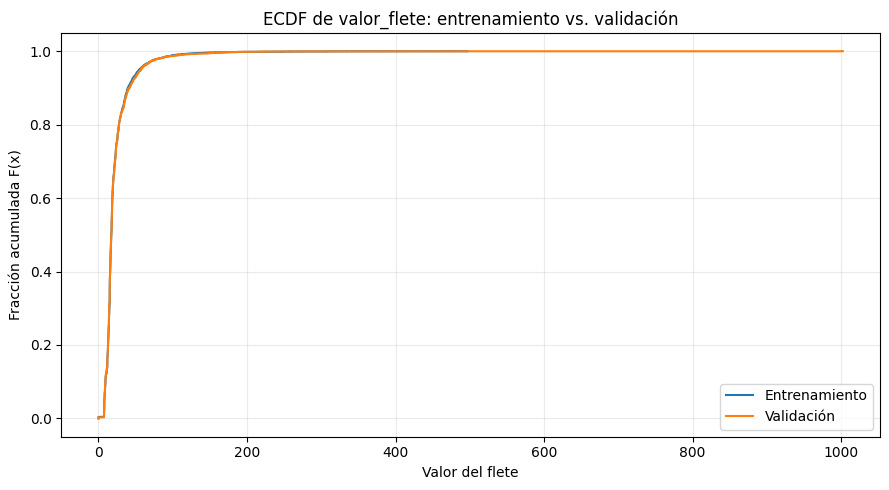

Limitación: KS clásico supone muestras independientes y se formula para distribuciones continuas. valor_flete puede contener empates por importes repetidos o redondeados; además, con muestras grandes diferencias pequeñas pueden producir valores p bajos. Interprete D junto con las gráficas y estadísticos descriptivos.


In [21]:
flete_train = train['valor_flete'].dropna().to_numpy()
flete_valid = valid['valor_flete'].dropna().to_numpy()

resultado_ks = ks_2samp(
    flete_train,
    flete_valid,
    alternative='two-sided',
    method='auto'
)
alpha_ks = 0.05

print('Comparación: valor_flete entre entrenamiento y validación')
print(f'n entrenamiento: {len(flete_train):,}')
print(f'n validación: {len(flete_valid):,}')
print(f'Estadístico D: {resultado_ks.statistic:.6f}')
print(f'Valor p: {resultado_ks.pvalue:.6g}')
print(f'Nivel de significancia: {alpha_ks}')

if resultado_ks.pvalue < alpha_ks:
    decision_ks = 'Rechazar H0'
    interpretacion_ks = ('Hay evidencia estadística de que las distribuciones de valor_flete '
                         'difieren entre entrenamiento y validación.')
else:
    decision_ks = 'No rechazar H0'
    interpretacion_ks = ('No hay evidencia suficiente para afirmar que las distribuciones '
                         'de valor_flete difieren. Esto no prueba que sean idénticas.')

print('Decisión:', decision_ks)
print('Interpretación:', interpretacion_ks)
print('\nResumen descriptivo:')
display(pd.DataFrame({
    'entrenamiento': pd.Series(flete_train).describe(),
    'validacion': pd.Series(flete_valid).describe()
}))

# Visualización de distribuciones empíricas (ECDF).
def ecdf(valores):
    x = np.sort(valores)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

x_tr, y_tr = ecdf(flete_train)
x_va, y_va = ecdf(flete_valid)
plt.figure(figsize=(9, 5))
plt.step(x_tr, y_tr, where='post', label='Entrenamiento')
plt.step(x_va, y_va, where='post', label='Validación')
plt.xlabel('Valor del flete')
plt.ylabel('Fracción acumulada F(x)')
plt.title('ECDF de valor_flete: entrenamiento vs. validación')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print('Limitación: KS clásico supone muestras independientes y se formula para '
      'distribuciones continuas. valor_flete puede contener empates por importes '
      'repetidos o redondeados; además, con muestras grandes diferencias pequeñas '
      'pueden producir valores p bajos. Interprete D junto con las gráficas y '
      'estadísticos descriptivos.')

## 8.7. Interpretación de resultados — completar con las salidas propias

No copie cifras de otro estudiante ni anticipe resultados. Complete las siguientes conclusiones con los valores que produjo su ejecución:

1. **PCA:** se partió de ___ variables numéricas y se conservaron ___ componentes para explicar ___ % de la varianza. Esto representa una reducción de ___ dimensiones. La reducción resume variabilidad, pero no garantiza mejor clasificación.
2. **PCA frente a la referencia:** compare B contra A. Indique qué pasó con Recall, F1, Average Precision, FP, FN y costo. Explique si la reducción de dimensionalidad ayudó o eliminó señal útil.
3. **Regularización:** compare C y D frente a B. Recuerde que `C=0.1` regulariza más que `C=1.0`, y `C=10.0` regulariza menos. Justifique si las diferencias observadas son relevantes para el negocio.
4. **Decisión empresarial:** identifique el modelo de menor costo y compárelo con el costo de no intervenir. Distinga la mejor métrica predictiva de la alternativa más económica.
5. **KS:** reporte D, valor p, tamaños de muestra y decisión a α=0.05. Explique por qué el resultado no valida el modelo ni demuestra igualdad de distribuciones.

Una mejora solo debe atribuirse al cambio que se modificó en el experimento. Una diferencia pequeña no demuestra superioridad estadística; los experimentos de esta actividad son una comparación controlada sobre validación, no una prueba formal de diferencia entre clasificadores.


## 8.8. Registro reproducible de Semana 14

Se conserva la bitácora en `reports/` con el ID, semilla, huella de muestra, número de componentes, configuraciones, métricas, costos y resultado KS. No se incluyen los datos originales ni la muestra completa. La prueba final permanece sin utilizar.


In [22]:
reporte_s14 = {
    'laboratorio': 'S14_PCA_regularizacion_KS',
    'id_estudiante': identificador,
    'semilla': int(semilla),
    'huella_muestra': huella_muestra,
    'n_muestra': int(len(muestra)),
    'n_train': int(len(train)),
    'n_valid': int(len(valid)),
    'n_test_reservado': int(len(test)),
    'columnas_numericas': columnas_numericas,
    'columnas_categoricas': columnas_categoricas,
    'pca': {
        'umbral_varianza': 0.90,
        'n_variables_numericas': int(len(columnas_numericas)),
        'n_componentes': int(n_componentes_90),
        'varianza_acumulada': float(porcentaje_retenido)
    },
    'experimentos': resultados_s14.reset_index().replace({np.nan: None}).to_dict(orient='records'),
    'costo_no_intervenir_brl': int(costo_no_intervenir_s14),
    'ks_valor_flete': {
        'n_train': int(len(flete_train)),
        'n_valid': int(len(flete_valid)),
        'estadistico_D': float(resultado_ks.statistic),
        'p_value': float(resultado_ks.pvalue),
        'alpha': float(alpha_ks),
        'decision': decision_ks
    },
    'nota': 'Costos FP/FN didácticos; resultados calculados solo en validación. Test reservado.'
}

ruta_s14 = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta_s14.parent.mkdir(parents=True, exist_ok=True)
ruta_s14.write_text(json.dumps(reporte_s14, indent=2, ensure_ascii=False, default=str),
                    encoding='utf-8')
print('Reporte Semana 14 guardado en:', ruta_s14)

# Descarga automática si se ejecuta en Google Colab.
try:
    from google.colab import files
    files.download(str(ruta_s14))
except Exception:
    print('Fuera de Colab, el archivo queda guardado en la carpeta reports/.')

Reporte Semana 14 guardado en: reports/S14_resultados_ID_27.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8.9. Autoverificación de Semana 14

Estas comprobaciones verifican que se ejecutaron los cuatro experimentos, que las métricas/costos corresponden a validación y que no se utilizó la prueba final para seleccionar el modelo.


In [23]:
assert list(resultados_s14.index) == ['A', 'B', 'C', 'D']
assert len(predicciones_s14) == 4 and len(probabilidades_s14) == 4
assert all(len(predicciones_s14[k]) == len(y_valid) for k in configuraciones_s14)
assert all(len(probabilidades_s14[k]) == len(y_valid) for k in configuraciones_s14)
assert all(np.isfinite(resultados_s14[c]).all()
           for c in ['accuracy', 'precision', 'recall', 'f1',
                     'roc_auc', 'average_precision', 'costo_brl'])
assert n_componentes_90 >= 1
assert porcentaje_retenido >= 0.90 - 1e-10
assert resultado_ks.statistic >= 0 and 0 <= resultado_ks.pvalue <= 1
assert len(test) == 5250  # reservado; no se predice ni se usa para seleccionar
print('Autoverificación Semana 14 superada. La partición de prueba sigue reservada.')

Autoverificación Semana 14 superada. La partición de prueba sigue reservada.
